In [8]:
from fairchem.core.datasets.ase_datasets import AseReadMultiStructureDataset
from fairchem.core.models.model_registry import model_name_to_local_file
from fairchem.core.common.relaxation.ase_utils import OCPCalculator

import yaml
import ase
import os

import torch
from ase import Atoms
from torch_geometric.data import Data
import ase.data
import numpy as np
from fairchem.core.datasets.ase_datasets import AseReadMultiStructureDataset
from fairchem.core.models.model_registry import model_name_to_local_file
from fairchem.core.common.relaxation.ase_utils import OCPCalculator
from fairchem.core.common.relaxation.ase_utils import OCPCalculator

import yaml
import typing

In [9]:
import numpy as np
from rich.console import Console
from rich.table import Table

def calculate_force_metrics(labels, preds):
    """
    Calculate MAE, Cosine Similarity, and Force Magnitude for each model.
    
    Args:
        labels (list): List of true forces for each molecule.
        preds (list): List of predicted forces for each model.
    
    Returns:
        dict: Dictionary with metrics for each model
    """
    # metrics = {}
    # model_names = [key for key in results.keys() if key != "labels"]
    
    # for model_name in model_names:
        # Initialize accumulators
    molecule_mae = []
    atom_cosine_sim = []
    atom_pred_magnitudes = []
    atom_true_magnitudes = []
        
    # Process each molecule
    for i in range(len(labels)):
        pred_forces = preds[i]
        true_forces = labels[i]
        
        # MAE calculation for this molecule
        mae = np.mean(np.abs(pred_forces - true_forces))
        molecule_mae.append(mae)
        
        # Force magnitude calculation (vectorized)
        pred_mags = np.linalg.norm(pred_forces, axis=1)
        true_mags = np.linalg.norm(true_forces, axis=1)
        atom_pred_magnitudes.extend(pred_mags)
        atom_true_magnitudes.extend(true_mags)
        
        # Cosine similarity calculation (vectorized)
        dot_products = np.sum(pred_forces * true_forces, axis=1)
        # Avoid division by zero
        valid_indices = (pred_mags > 1e-10) & (true_mags > 1e-10)
        if np.any(valid_indices):
            cos_sims = np.zeros(len(pred_mags))
            cos_sims[valid_indices] = dot_products[valid_indices] / (pred_mags[valid_indices] * true_mags[valid_indices])
            atom_cosine_sim.extend(cos_sims[valid_indices])
    
        # Compute final metrics
        metrics = {
            "MAE": np.mean(molecule_mae),
            "Mean_Pred_Magnitude": np.mean(atom_pred_magnitudes),
            "Mean_True_Magnitude": np.mean(atom_true_magnitudes),
            "MAE_Magnitude": np.mean(np.abs(np.array(atom_pred_magnitudes) - np.array(atom_true_magnitudes))),
            "Mean_Cosine_Similarity": np.mean(atom_cosine_sim) if atom_cosine_sim else np.nan
        }
    
    return metrics

# Display results in a nice table
def display_metrics_table(metrics):
    console = Console()
    table = Table(title="Force Prediction Metrics")
    
    table.add_column("Model", style="cyan")
    table.add_column("MAE (Hartree)", style="green")
    table.add_column("Mean Cosine Sim", style="yellow")
    table.add_column("Mean Force Mag", style="magenta")
    
    for model_name, model_metrics in metrics.items():
        table.add_row(
            model_name,
            f"{model_metrics['MAE']:.4f}",
            f"{model_metrics['Mean_Cosine_Similarity']:.4f}",
            f"{model_metrics['Mean_Pred_Magnitude']:.4f}"
        )
    
    console.print(table)

In [10]:
# Calculate energy metrics
def calculate_energy_metrics(labels, preds):
    """
    Calculate MAE for energy predictions.
    
    Args:
        labels (list): List of true energies for each molecule.
        preds (list): List of predicted energies for each model.
    """
    mae = np.mean(np.abs(np.array(labels) - np.array(preds)))
    return {"MAE": mae}

# Display energy results in a nice table
def display_energy_metrics_table(metrics):
    console = Console()
    table = Table(title="Energy Prediction Metrics")
    
    table.add_column("Model", style="cyan")
    table.add_column("MAE (Hartree)", style="green")
    
    for model_name, model_metrics in metrics.items():
        table.add_row(
            model_name,
            f"{model_metrics['MAE']:.4f}"
        )
    
    console.print(table)

In [2]:
models_dict = {
    "EquiFormerV2": {
        "config": "generalisation_checkpoints/repetitation_generalisation/configs/equiformer2.yml",
        "ckpt": "generalisation_checkpoints/repetitation_generalisation/EquiFormerV2/checkpoint.pt"
    },
    "PAINN": {
        "config": "generalisation_checkpoints/repetitation_generalisation/configs/painn.yml",
        "ckpt": "generalisation_checkpoints/repetitation_generalisation/PAINN/checkpoint.pt"
    },
    "DimeNet++": {
        "config": "generalisation_checkpoints/repetitation_generalisation/configs/dpp10.7M.yml",
        "ckpt": "generalisation_checkpoints/repetitation_generalisation/DPP/checkpoint.pt"
    },
    # "eSCN": {
    #     "config": "generalisation_checkpoints/length_generalisation/configs/escn.yml",
    #     "ckpt": "generalisation_checkpoints/length_generalisation/eSCN/checkpoint.pt"
    # },
    "SchNet": {
        "config": "generalisation_checkpoints/repetitation_generalisation/configs/schnet.yml",
        "ckpt": "generalisation_checkpoints/repetitation_generalisation/SchNet/checkpoint.pt"
    },
    "GemNet": {
        "config": "generalisation_checkpoints/repetitation_generalisation/configs/gemnet.yml",
        "ckpt": "generalisation_checkpoints/repetitation_generalisation/GemNet/checkpoint.pt"
    },
}

In [3]:
for i in os.listdir("databases/Experiment-1-Analysing"):
    print(i)

NameError: name 'os' is not defined

In [13]:
# Loading the dataset per each molecule
dataset_dict = {}
for i in os.listdir("databases/Experiment-1-Analysing"):
    dataset_dict[f"{i}"] = {}
    dataset_dict[f"{i}"]["dataset"] = AseReadMultiStructureDataset({"src": f"databases/Experiment-1-Analysing/{i}",
                                     'pattern': '*.traj',
                                     'a2g_args': {'r_energy': True, 'r_forces': True},
                                     'key_mapping': {'atoms': 'atomic_numbers'}})
    dataset_dict[f"{i}"]["symbols"] = [ase.data.chemical_symbols[z.item()] for z in dataset_dict[f"{i}"]["dataset"][0].atomic_numbers]

100%|██████████| 1/1 [00:00<00:00, 50.15it/s]


In [14]:
for model_setting in models_dict:
    model = OCPCalculator(
        config_yml= models_dict[model_setting]["config"],
        checkpoint_path= models_dict[model_setting]["ckpt"],
        cpu=False,
        trainer="equiformerv2_forces"
    )
    models_dict[model_setting]["model"] = model

/home/masoud/Projects/SCAI/src/fairchem/core/models/scn/spherical_harmonics.py:23: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  _Jd = torch.load(os.path.join(os.path.dirnam

In [15]:
# Apply each model to each dataset and collect results
results = {}
for model_setting in models_dict:
    model = models_dict[model_setting]["model"]
    results[model_setting] = {"forces": [], "force_preds": [], "energy": [], "energy_preds": []}
    
    for molecule_name, molecule_data in dataset_dict.items():
        dataset = molecule_data["dataset"]
        symbols = molecule_data["symbols"]
        
        for data in dataset:
            # Convert ASE Atoms to PyG Data
            atoms = Atoms(symbols=symbols,
                          positions=data.pos.numpy(),
                          cell=data.cell.numpy().reshape(3, 3))
            
            results[model_setting]["forces"].append(data.forces.numpy())
            results[model_setting]["energy"].append(data.energy)
            
            atoms.calc = model
            # These next two lines are needed for GemNet because it uses Quadruplets
            tags = np.ones(len(atoms))
            atoms.set_tags(tags)
            # energy = atoms.get_potential_energy()
            forces = atoms.get_forces()
            energy = atoms.get_potential_energy()

            # Store results
            results[model_setting]["force_preds"].append(forces)
            results[model_setting]["energy_preds"].append(energy)

/home/masoud/Projects/SCAI/src/fairchem/core/models/dimenet_plus_plus.py:445: UserWarning: Using torch.cross without specifying the dim arg is deprecated.
Please either pass the dim explicitly or simply use torch.linalg.cross.
The default value of dim will change to agree with that of linalg.cross in a future release. (Triggered internally at /opt/conda/conda-bld/pytorch_1720538456841/work/aten/src/ATen/native/Cross.cpp:62.)
  b = torch.cross(pos_ji, pos_kj).norm(dim=-1)


In [33]:
len(results["PAINN"]["energy"]) / 12

100.0

In [16]:
# Convertiing results to metrics
from collections import defaultdict
forces_metrics = defaultdict(list)
energy_metrics = defaultdict(list)
for model_name, model_results in results.items():
    if len(model_results["forces"]) > 0 and len(model_results["energy"]) > 0:
        forces = model_results["forces"]
        force_preds = model_results["force_preds"]
        energy = model_results["energy"]
        energy_preds = model_results["energy_preds"]

        # split the list into chunks of 100
        forces_chunks = [forces[i:i + 100] for i in range(0, len(forces), 100)]
        force_preds_chunks = [force_preds[i:i + 100] for i in range(0, len(force_preds), 100)]
        energy_chunks = [energy[i:i + 100] for i in range(0, len(energy), 100)]
        energy_preds_chunks = [energy_preds[i:i + 100] for i in range(0, len(energy_preds), 100)]
        # Calculate metrics for each chunk
        for forces_chunk, force_preds_chunk in zip(forces_chunks, force_preds_chunks):
            metrics_chunk = calculate_force_metrics(forces_chunk, force_preds_chunk)
            forces_metrics[model_name].append(metrics_chunk)

        for energy_chunk, energy_preds_chunk in zip(energy_chunks, energy_preds_chunks):
            metrics_chunk = calculate_energy_metrics(energy_chunk, energy_preds_chunk)
            energy_metrics[model_name].append(metrics_chunk)


In [17]:
# Updated data processing to include the new model
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np

# Extract data from the updated results dictionary
energy_plot_data = []
molecule_names = [f"C{i+2}H{2*(i+2)+2}" for i in range(12)]

for model_name, model_results in energy_metrics.items():
    for i, result in enumerate(model_results):

        energy_plot_data.append({
            'Model': model_name,
            'Molecule_Index': i + 1,
            'Molecule': molecule_names[i],
            'MAE': result['MAE'],
        })

energy_df_updated = pd.DataFrame(energy_plot_data)

# Extended color palette for more models
colors_extended = ['blue', 'red', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan']
model_colors_updated = {model: colors_extended[i] for i, model in enumerate(energy_df_updated['Model'].unique())}

print("Updated data processed successfully!")
print(f"Total data points: {len(energy_df_updated)}")
print(f"Models: {energy_df_updated['Model'].unique()}")
print(f"Model colors: {model_colors_updated}")
energy_df_updated.head(10)

Updated data processed successfully!
Total data points: 60
Models: ['EquiFormerV2' 'PAINN' 'DimeNet++' 'SchNet' 'GemNet']
Model colors: {'EquiFormerV2': 'blue', 'PAINN': 'red', 'DimeNet++': 'green', 'SchNet': 'orange', 'GemNet': 'purple'}


,Model,Molecule_Index,Molecule,MAE
0,EquiFormerV2,1,C2H6,0.003412
1,EquiFormerV2,2,C3H8,0.005986
2,EquiFormerV2,3,C4H10,0.013903
3,EquiFormerV2,4,C5H12,0.021183
4,EquiFormerV2,5,C6H14,0.026465
5,EquiFormerV2,6,C7H16,3.022669
6,EquiFormerV2,7,C8H18,7.994597
7,EquiFormerV2,8,C9H20,12.073726
8,EquiFormerV2,9,C10H22,16.388548
9,EquiFormerV2,10,C11H24,22.101699


In [19]:
# Updated data processing to include the new model
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np

# Extract data from the updated results dictionary
forces_plot_data = []
molecule_names = [f"C{i+2}H{2*(i+2)+2}" for i in range(12)]

for model_name, model_results in forces_metrics.items():
    for i, result in enumerate(model_results):

        forces_plot_data.append({
            'Model': model_name,
            'Molecule_Index': i + 1,
            'Molecule': molecule_names[i],
            'MAE': result['MAE'],
            'Cosine_Similarity': result['Mean_Cosine_Similarity'],
            'Magnitude_MAE': result['MAE_Magnitude']
        })

forces_df_updated = pd.DataFrame(forces_plot_data)

# Extended color palette for more models
colors_extended = ['blue', 'red', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan']
model_colors_updated = {model: colors_extended[i] for i, model in enumerate(forces_df_updated['Model'].unique())}

print("Updated data processed successfully!")
print(f"Total data points: {len(forces_df_updated)}")
print(f"Models: {forces_df_updated['Model'].unique()}")
print(f"Model colors: {model_colors_updated}")
forces_df_updated.head(10)

Updated data processed successfully!
Total data points: 60
Models: ['EquiFormerV2' 'PAINN' 'DimeNet++' 'SchNet' 'GemNet']
Model colors: {'EquiFormerV2': 'blue', 'PAINN': 'red', 'DimeNet++': 'green', 'SchNet': 'orange', 'GemNet': 'purple'}


,Model,Molecule_Index,Molecule,MAE,Cosine_Similarity,Magnitude_MAE
0,EquiFormerV2,1,C2H6,0.000292,1.000000,0.000392
1,EquiFormerV2,2,C3H8,0.000360,1.000000,0.000447
2,EquiFormerV2,3,C4H10,0.000438,1.000000,0.000510
3,EquiFormerV2,4,C5H12,0.000444,1.000000,0.000508
4,EquiFormerV2,5,C6H14,0.000488,1.000000,0.000554
5,EquiFormerV2,6,C7H16,0.002215,0.999913,0.003177
6,EquiFormerV2,7,C8H18,0.002391,0.999984,0.003221
7,EquiFormerV2,8,C9H20,0.002319,0.999974,0.002748
8,EquiFormerV2,9,C10H22,0.002331,0.999986,0.002707
9,EquiFormerV2,10,C11H24,0.002536,0.999982,0.002941


In [29]:
forces_df_updated

,Model,Molecule_Index,Molecule,MAE,Cosine_Similarity,Magnitude_MAE
0,EquiFormerV2,1,C2H6,0.000292,1.000000,0.000392
1,EquiFormerV2,2,C3H8,0.000360,1.000000,0.000447
2,EquiFormerV2,3,C4H10,0.000438,1.000000,0.000510
3,EquiFormerV2,4,C5H12,0.000444,1.000000,0.000508
4,EquiFormerV2,5,C6H14,0.000488,1.000000,0.000554
5,EquiFormerV2,6,C7H16,0.002215,0.999913,0.003177
6,EquiFormerV2,7,C8H18,0.002391,0.999984,0.003221
7,EquiFormerV2,8,C9H20,0.002319,0.999974,0.002748
8,EquiFormerV2,9,C10H22,0.002331,0.999986,0.002707
9,EquiFormerV2,10,C11H24,0.002536,0.999982,0.002941


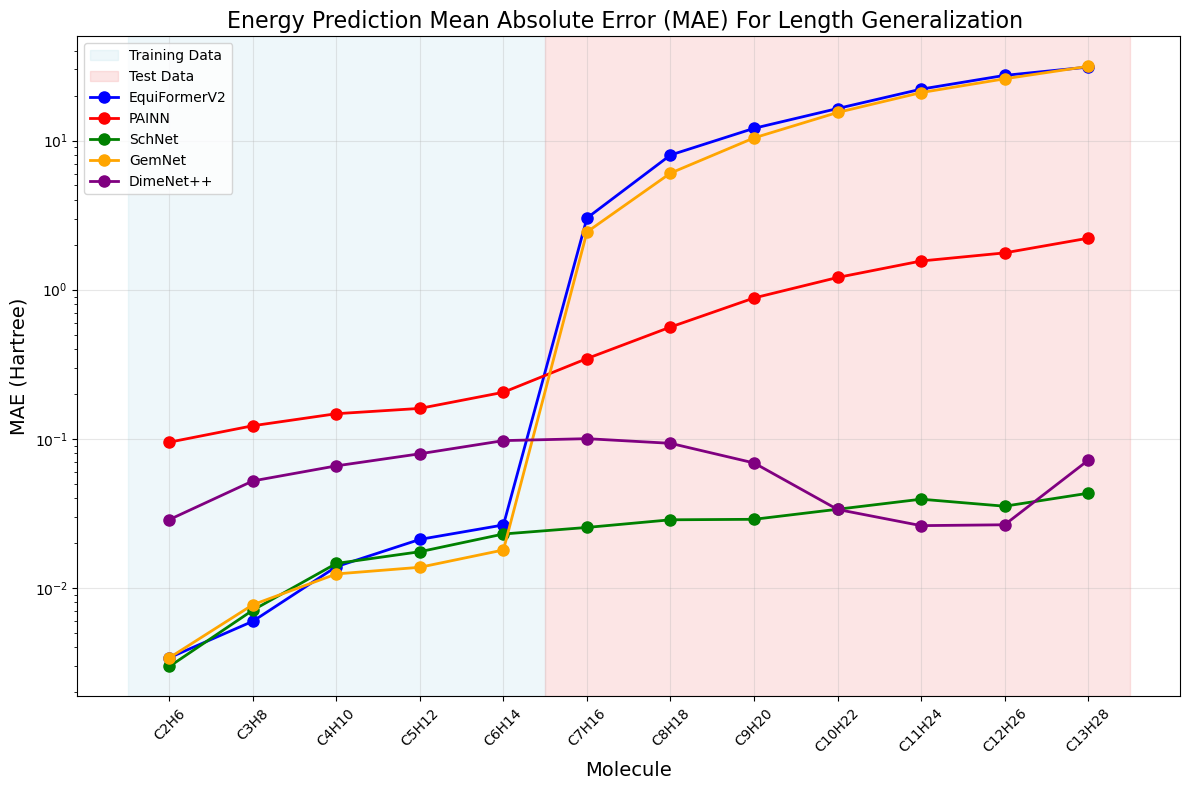

In [72]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.patches import Rectangle

# Set up the plot
plt.figure(figsize=(12, 8))

# Define molecule names
molecule_names = ['C2H6', 'C3H8', 'C4H10', 'C5H12', 'C6H14', 'C7H16', 'C8H18', 'C9H20', 'C10H22', 'C11H24', 'C12H26', 'C13H28']

# Add background rectangles
plt.axvspan(-0.5, 4.5, alpha=0.2, color='lightblue', label='Training Data')
plt.axvspan(4.5, 11.5, alpha=0.2, color='lightcoral', label='Test Data')

# Plot each model
for model in energy_df_updated['Model'].unique():
    model_data = energy_df_updated[energy_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        x_coords = range(len(molecule_names))
        y_coords = model_data['MAE'].values
        plt.plot(x_coords, y_coords, marker='o', markersize=8, linewidth=2, 
                color=model_colors_updated[model], label=model)

# Set plot properties
plt.xlabel('Molecule', fontsize=14)
plt.ylabel('MAE (Hartree)', fontsize=14)
plt.title('Energy Prediction Mean Absolute Error (MAE) For Length Generalization ', fontsize=16)
plt.xticks(range(len(molecule_names)), molecule_names, rotation=45)
plt.yscale('log')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

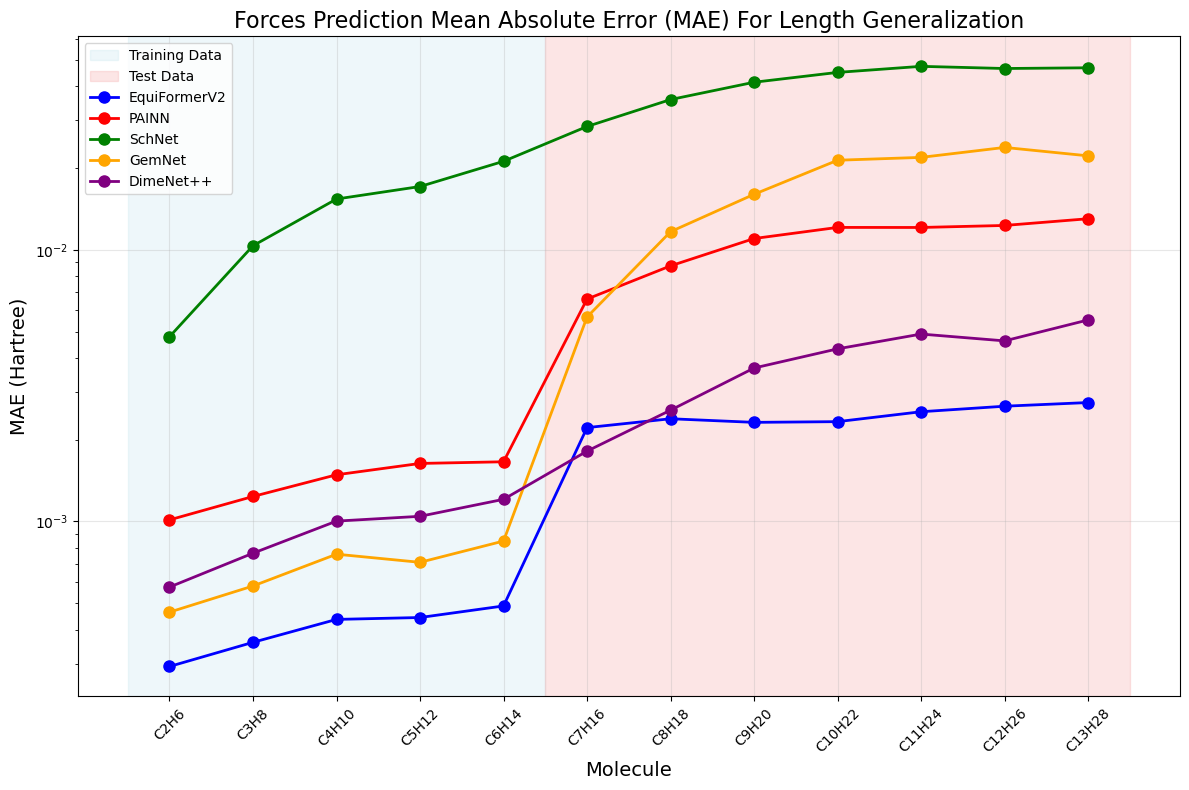

In [73]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.patches import Rectangle

# Set up the plot
plt.figure(figsize=(12, 8))

# Define molecule names
molecule_names = ['C2H6', 'C3H8', 'C4H10', 'C5H12', 'C6H14', 'C7H16', 'C8H18', 'C9H20', 'C10H22', 'C11H24', 'C12H26', 'C13H28']

# Add background rectangles
plt.axvspan(-0.5, 4.5, alpha=0.2, color='lightblue', label='Training Data')
plt.axvspan(4.5, 11.5, alpha=0.2, color='lightcoral', label='Test Data')

# Plot each model
for model in forces_df_updated['Model'].unique():
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        x_coords = range(len(molecule_names))
        y_coords = model_data['MAE'].values
        plt.plot(x_coords, y_coords, marker='o', markersize=8, linewidth=2, 
                color=model_colors_updated[model], label=model)

# Set plot properties
plt.xlabel('Molecule', fontsize=14)
plt.ylabel('MAE (Hartree)', fontsize=14)
plt.title('Forces Prediction Mean Absolute Error (MAE) For Length Generalization', fontsize=16)
plt.xticks(range(len(molecule_names)), molecule_names, rotation=45)
plt.yscale('log')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

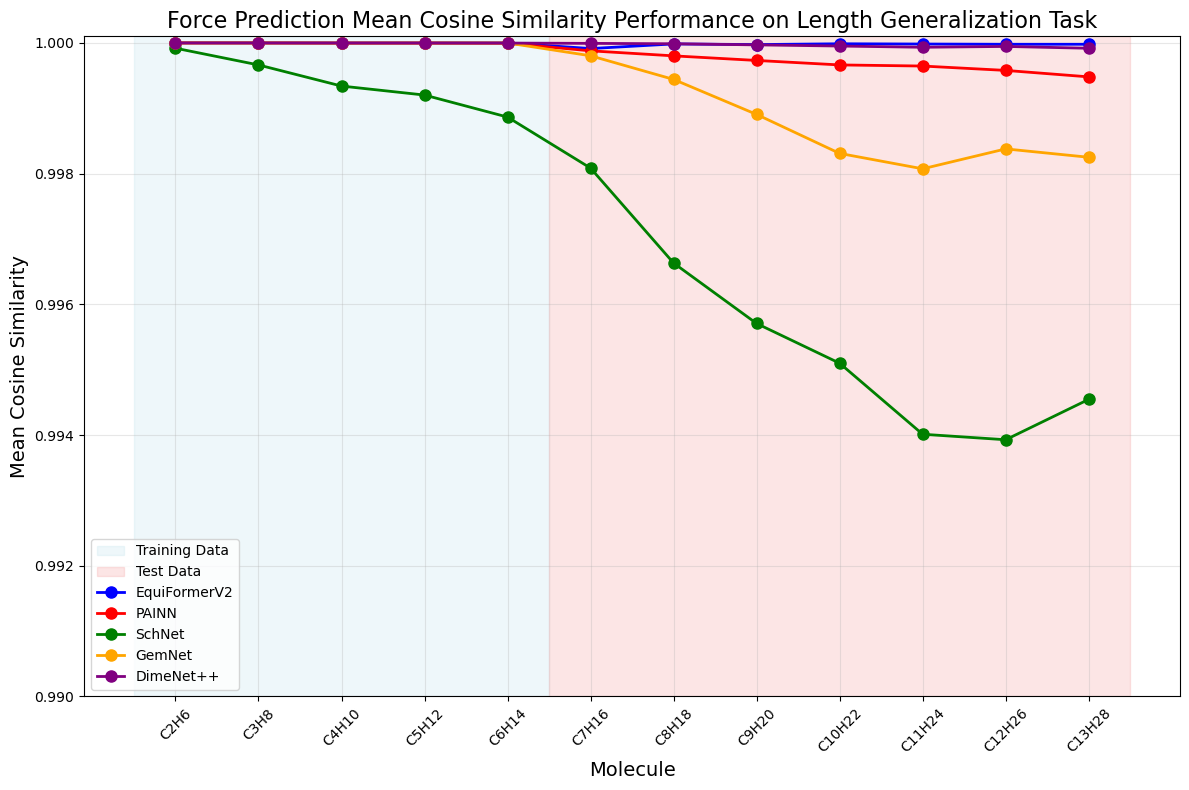

In [74]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Set up the plot
plt.figure(figsize=(12, 8))

# Define molecule names
molecule_names = ['C2H6', 'C3H8', 'C4H10', 'C5H12', 'C6H14', 'C7H16', 'C8H18', 'C9H20', 'C10H22', 'C11H24', 'C12H26', 'C13H28']

# Add background rectangles
plt.axvspan(-0.5, 4.5, alpha=0.2, color='lightblue', label='Training Data')
plt.axvspan(4.5, 11.5, alpha=0.2, color='lightcoral', label='Test Data')

# Plot each model
for model in df_updated['Model'].unique():
    model_data = df_updated[df_updated['Model'] == model]
    x_coords = range(len(molecule_names))
    y_coords = model_data['Cosine_Similarity'].values
    plt.plot(x_coords, y_coords, marker='o', markersize=8, linewidth=2, 
            color=model_colors_updated[model], label=model)

# Set plot properties
plt.xlabel('Molecule', fontsize=14)
plt.ylabel('Mean Cosine Similarity', fontsize=14)
plt.title('Force Prediction Mean Cosine Similarity Performance on Length Generalization Task', fontsize=16)
plt.xticks(range(len(molecule_names)), molecule_names, rotation=45)
plt.ylim(0.99, 1.0001)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

INFO:fontTools.subset:maxp pruned
INFO:fontTools.subset:cmap pruned
INFO:fontTools.subset:kern dropped
INFO:fontTools.subset:post pruned
INFO:fontTools.subset:FFTM dropped
INFO:fontTools.subset:GPOS pruned
INFO:fontTools.subset:GSUB pruned
INFO:fontTools.subset:glyf pruned
INFO:fontTools.subset:Added gid0 to subset
INFO:fontTools.subset:Added first four glyphs to subset
INFO:fontTools.subset:Closing glyph list over 'GSUB': 29 glyphs before
INFO:fontTools.subset:Glyph names: ['.notdef', '.null', 'A', 'C', 'E', 'F', 'M', 'S', 'T', 'a', 'b', 'c', 'd', 'e', 'g', 'i', 'l', 'm', 'n', 'nonmarkingreturn', 'o', 'parenleft', 'parenright', 'r', 's', 'space', 't', 'u', 'y']
INFO:fontTools.subset:Glyph IDs:   [0, 1, 2, 3, 11, 12, 36, 38, 40, 41, 48, 54, 55, 68, 69, 70, 71, 72, 74, 76, 79, 80, 81, 82, 85, 86, 87, 88, 92]
INFO:fontTools.subset:Closed glyph list over 'GSUB': 29 glyphs after
INFO:fontTools.subset:Glyph names: ['.notdef', '.null', 'A', 'C', 'E', 'F', 'M', 'S', 'T', 'a', 'b', 'c', 'd', '

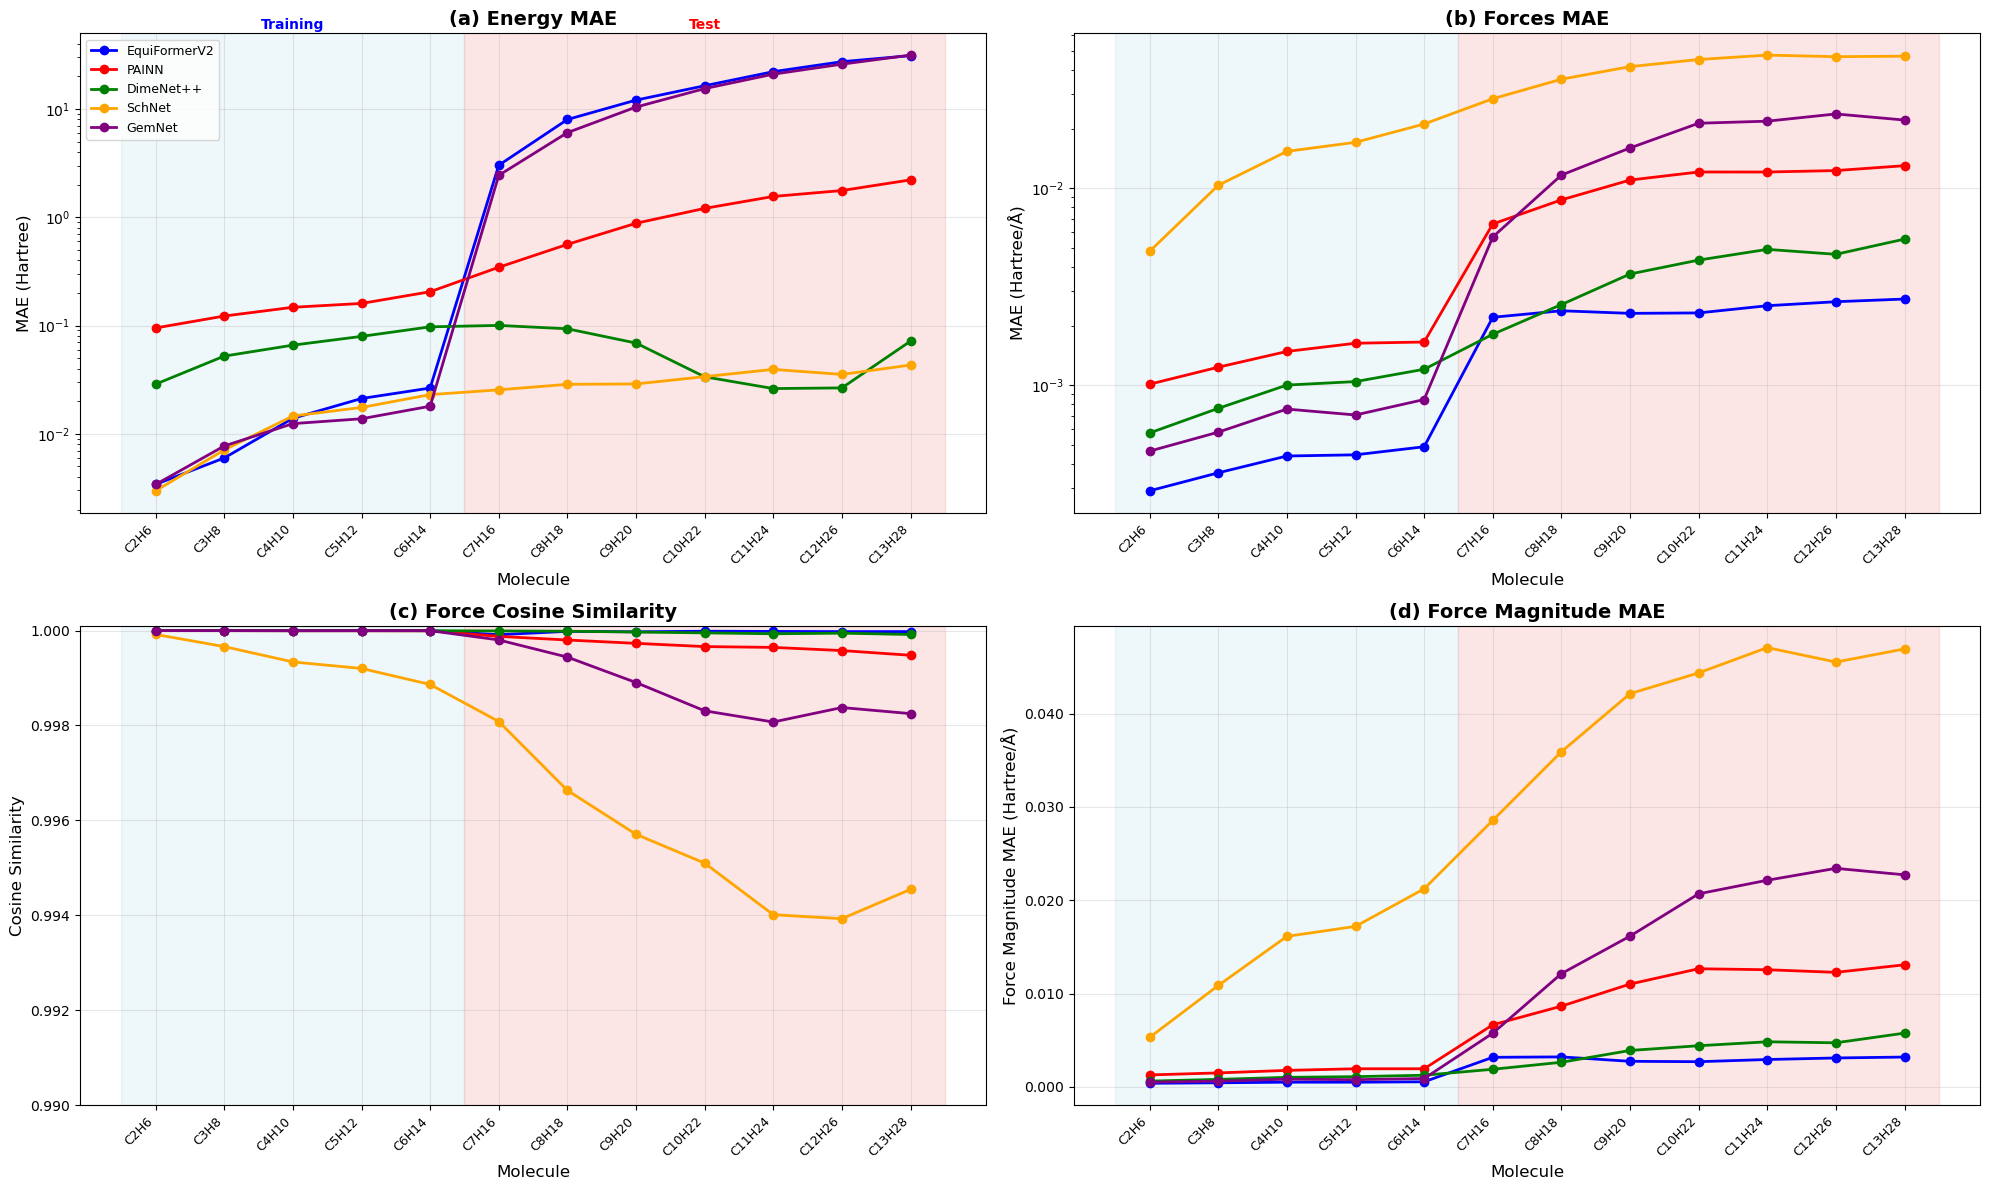

In [42]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Set up the figure with three subplots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 12))

# Define molecule names
molecule_names = ['C2H6', 'C3H8', 'C4H10', 'C5H12', 'C6H14', 'C7H16', 'C8H18', 'C9H20', 'C10H22', 'C11H24', 'C12H26', 'C13H28']

# Subplot 1: Energy MAE
ax1.axvspan(-0.5, 4.5, alpha=0.2, color='lightblue')
ax1.axvspan(4.5, 11.5, alpha=0.2, color='lightcoral')
for model in energy_df_updated['Model'].unique():
    model_data = energy_df_updated[energy_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        x_coords = range(len(molecule_names))
        y_coords = model_data['MAE'].values
        ax1.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
                color=model_colors_updated[model], label=model)
ax1.set_xlabel('Molecule', fontsize=12)
ax1.set_ylabel('MAE (Hartree)', fontsize=12)
ax1.set_title('(a) Energy MAE', fontsize=14, fontweight='bold')
ax1.set_xticks(range(len(molecule_names)))
ax1.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax1.set_yscale('log')
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=9)

# Subplot 2: Forces MAE
ax2.axvspan(-0.5, 4.5, alpha=0.2, color='lightblue')
ax2.axvspan(4.5, 11.5, alpha=0.2, color='lightcoral')
for model in forces_df_updated['Model'].unique():
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        x_coords = range(len(molecule_names))
        y_coords = model_data['MAE'].values
        ax2.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
                color=model_colors_updated[model])
ax2.set_xlabel('Molecule', fontsize=12)
ax2.set_ylabel('MAE (Hartree/Å)', fontsize=12)
ax2.set_title('(b) Forces MAE', fontsize=14, fontweight='bold')
ax2.set_xticks(range(len(molecule_names)))
ax2.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3)

# Subplot 3: Cosine Similarity
ax3.axvspan(-0.5, 4.5, alpha=0.2, color='lightblue')
ax3.axvspan(4.5, 11.5, alpha=0.2, color='lightcoral')
for model in forces_df_updated['Model'].unique():
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    x_coords = range(len(molecule_names))
    y_coords = model_data['Cosine_Similarity'].values
    ax3.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
            color=model_colors_updated[model])
ax3.set_xlabel('Molecule', fontsize=12)
ax3.set_ylabel('Cosine Similarity', fontsize=12)
ax3.set_title('(c) Force Cosine Similarity', fontsize=14, fontweight='bold')
ax3.set_xticks(range(len(molecule_names)))
ax3.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax3.set_ylim(0.99, 1.0001)
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
ax3.grid(True, alpha=0.3)


# Subplot 4: Force Magnitude MAE
ax4.axvspan(-0.5, 4.5, alpha=0.2, color='lightblue')
ax4.axvspan(4.5, 11.5, alpha=0.2, color='lightcoral')
for model in forces_df_updated['Model'].unique():
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    x_coords = range(len(molecule_names))
    y_coords = model_data['Magnitude_MAE'].values
    ax4.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
            color=model_colors_updated[model])
ax4.set_xlabel('Molecule', fontsize=12)
ax4.set_ylabel('Force Magnitude MAE (Hartree/Å)', fontsize=12)
ax4.set_title('(d) Force Magnitude MAE', fontsize=14, fontweight='bold')
ax4.set_xticks(range(len(molecule_names)))
ax4.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
# ax4.set_ylim(0.99, 1.0001)
ax4.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
ax4.grid(True, alpha=0.3)

# Add training/test labels only once
ax1.text(2, ax1.get_ylim()[1]*1.09, 'Training', ha='center', fontsize=10, fontweight='bold', color='blue')
ax1.text(8, ax1.get_ylim()[1]*1.09, 'Test', ha='center', fontsize=10, fontweight='bold', color='red')

plt.tight_layout()
# Save to PDF with selectable text
plt.savefig('generalisation_checkpoints/length_generalisation/length_generalisation_figure_1.pdf', format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()

KeyError: 'Force_Magnitude_MAE'

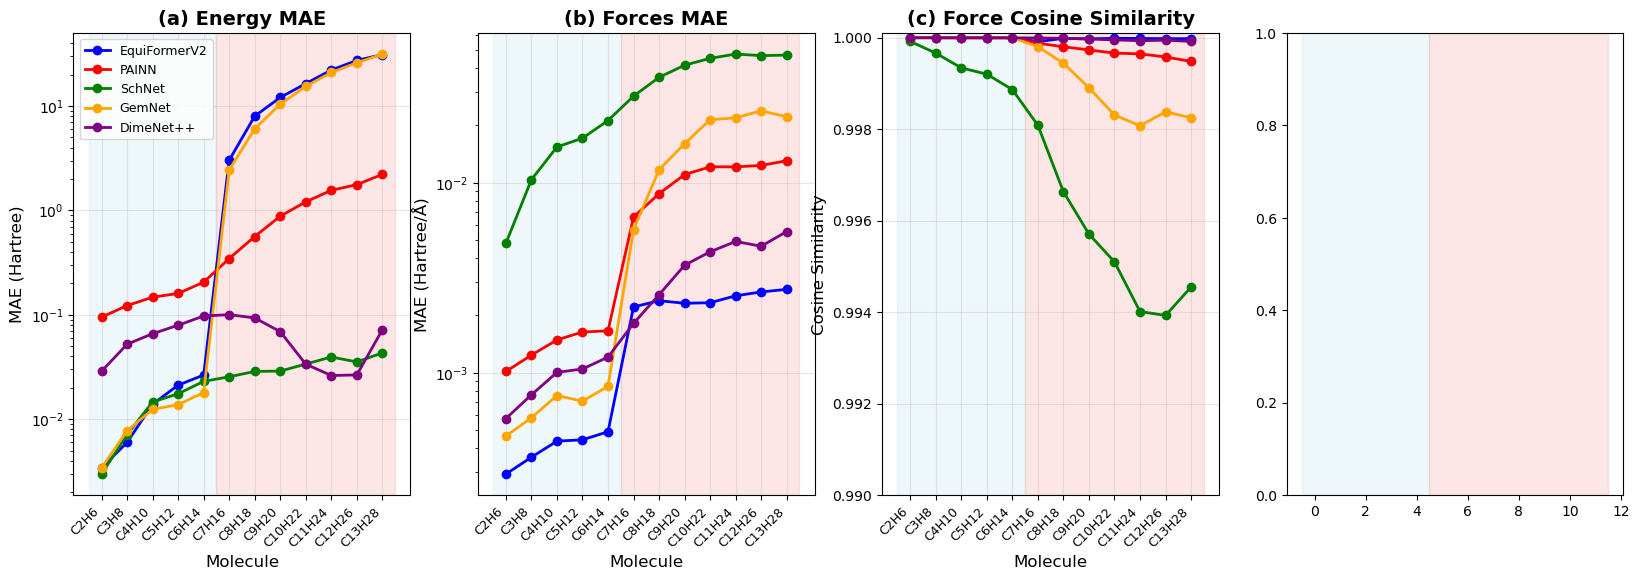

In [ ]:
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42  # Enable selectable text in PDF

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Set up the figure with three subplots
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(20, 6))

# Define molecule names
molecule_names = ['C2H6', 'C3H8', 'C4H10', 'C5H12', 'C6H14', 'C7H16', 'C8H18', 'C9H20', 'C10H22', 'C11H24', 'C12H26', 'C13H28']

# Subplot 1: Energy MAE
ax1.axvspan(-0.5, 4.5, alpha=0.2, color='lightblue')
ax1.axvspan(4.5, 11.5, alpha=0.2, color='lightcoral')
for model in energy_df_updated['Model'].unique():
    model_data = energy_df_updated[energy_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        x_coords = range(len(molecule_names))
        y_coords = model_data['MAE'].values
        ax1.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
                color=model_colors_updated[model], label=model)
ax1.set_xlabel('Molecule', fontsize=12)
ax1.set_ylabel('MAE (Hartree)', fontsize=12)
ax1.set_title('(a) Energy MAE', fontsize=14, fontweight='bold')
ax1.set_xticks(range(len(molecule_names)))
ax1.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax1.set_yscale('log')
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=9)

# Subplot 2: Forces MAE
ax2.axvspan(-0.5, 4.5, alpha=0.2, color='lightblue')
ax2.axvspan(4.5, 11.5, alpha=0.2, color='lightcoral')
for model in forces_df_updated['Model'].unique():
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        x_coords = range(len(molecule_names))
        y_coords = model_data['MAE'].values
        ax2.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
                color=model_colors_updated[model])
ax2.set_xlabel('Molecule', fontsize=12)
ax2.set_ylabel('MAE (Hartree/Å)', fontsize=12)
ax2.set_title('(b) Forces MAE', fontsize=14, fontweight='bold')
ax2.set_xticks(range(len(molecule_names)))
ax2.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3)

# Subplot 3: Cosine Similarity
ax3.axvspan(-0.5, 4.5, alpha=0.2, color='lightblue')
ax3.axvspan(4.5, 11.5, alpha=0.2, color='lightcoral')
for model in forces_df_updated['Model'].unique():
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    x_coords = range(len(molecule_names))
    y_coords = model_data['Cosine_Similarity'].values
    ax3.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
            color=model_colors_updated[model])
ax3.set_xlabel('Molecule', fontsize=12)
ax3.set_ylabel('Cosine Similarity', fontsize=12)
ax3.set_title('(c) Force Cosine Similarity', fontsize=14, fontweight='bold')
ax3.set_xticks(range(len(molecule_names)))
ax3.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax3.set_ylim(0.99, 1.0001)
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
ax3.grid(True, alpha=0.3)


# Subplot 4: Force Magnitude MAE
ax4.axvspan(-0.5, 4.5, alpha=0.2, color='lightblue')
ax4.axvspan(4.5, 11.5, alpha=0.2, color='lightcoral')
for model in forces_df_updated['Model'].unique():
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    x_coords = range(len(molecule_names))
    y_coords = model_data['Force_Magnitude_MAE'].values
    ax4.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
            color=model_colors_updated[model])
ax4.set_xlabel('Molecule', fontsize=12)
ax4.set_ylabel('Force Magnitude MAE (Hartree/Å)', fontsize=12)
ax4.set_title('(d) Force Magnitude MAE', fontsize=14, fontweight='bold')
ax4.set_xticks(range(len(molecule_names)))
ax4.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax4.set_ylim(0.99, 1.0001)
ax4.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
ax4.grid(True, alpha=0.3)

# Add training/test labels only once
ax1.text(2, ax1.get_ylim()[1]*0.9, 'In-distribution', ha='center', fontsize=10, fontweight='bold', color='blue')
ax1.text(8, ax1.get_ylim()[1]*0.9, 'Out-of-distribution', ha='center', fontsize=10, fontweight='bold', color='red')

plt.tight_layout()




In [82]:
import pickle

# Save your dictionaries
data_to_save = {
    'energy_df_updated': energy_df_updated,
    'forces_df_updated': forces_df_updated,
    'model_colors_updated': model_colors_updated
}

# Save
with open('generalisation_checkpoints/length_generalisation/plot_data.pkl', 'wb') as f:
    pickle.dump(data_to_save, f)



In [5]:
import pickle
# Load later
with open('generalisation_checkpoints/length_generalisation/plot_data.pkl', 'rb') as f:
    loaded_data = pickle.load(f)
    
energy_df_updated = loaded_data['energy_df_updated']
forces_df_updated = loaded_data['forces_df_updated']
model_colors_updated = loaded_data['model_colors_updated']

In [53]:
# Create updated MAE plot with all models including the new one
fig_mae_updated = go.Figure()

# Add traces for each model including the new one
for model in df_updated['Model'].unique():
    model_data = df_updated[df_updated['Model'] == model]
    
    # Skip models with all NaN values
    if not model_data['MAE'].isna().all():
        fig_mae_updated.add_trace(go.Scatter(
            x=model_data['Molecule'],  # Use molecule symbols instead of indices
            y=model_data['MAE'],
            mode='markers+lines',
            name=model,
            line=dict(color=model_colors_updated[model]),
            marker=dict(size=8, color=model_colors_updated[model])
        ))

# Update layout for MAE plot
fig_mae_updated.update_layout(
    title="Mean Absolute Error (MAE) For Length Generalization",
    xaxis_title="Molecule",
    yaxis_title="MAE (Hartree)",
    template="plotly_white",
    font=dict(size=12),
    legend=dict(
        x=0.02,
        y=0.8,
        xanchor='left',
        yanchor='top',
        bgcolor='rgba(255, 255, 255, 0.8)',
        bordercolor='rgba(0, 0, 0, 0.2)',
        borderwidth=1
    ),
    width=900,
    height=500
)

# Add background rectangles - blue for train data, red for test data
molecule_names = ['C2H6', 'C3H8', 'C4H10', 'C5H12', 'C6H14', 'C7H16', 'C8H18', 'C9H20', 'C10H22', 'C11H24', 'C12H26', 'C13H28']
num_molecules = len(molecule_names)

# Train data background (first 5 molecules: C2H6 to C6H14)
fig_mae_updated.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=0, y1=1,
              fillcolor="LightSkyBlue", opacity=0.2,
              layer="below", line_width=0, yref="paper")

# Test data background (last 7 molecules: C7H16 to C13H28)  
fig_mae_updated.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=0, y1=1,
              fillcolor="LightCoral", opacity=0.2,
              layer="below", line_width=0, yref="paper")

# Rotate x-axis labels for better readability
fig_mae_updated.update_xaxes(tickangle=45)

# Set y-axis to log scale for better visualization
fig_mae_updated.update_yaxes(type="log")  

fig_mae_updated.show()

In [56]:
# Create updated Cosine Similarity plot with all models including the new one
fig_cos_updated = go.Figure()

# Add traces for each model including the new one
for model in df_updated['Model'].unique():
    model_data = df_updated[df_updated['Model'] == model]
    
    # Include all data since NaN values have been replaced with 0
    fig_cos_updated.add_trace(go.Scatter(
        x=model_data['Molecule'],  # Use molecule symbols instead of indices
        y=model_data['Cosine_Similarity'],
        mode='markers+lines',
        name=model,
        line=dict(color=model_colors_updated[model]),
        marker=dict(size=8, color=model_colors_updated[model])
    ))

# Update layout for Cosine Similarity plot
fig_cos_updated.update_layout(
    title="Mean Cosine Similarity Across Molecules for Different Models (Updated)",
    xaxis_title="Molecule",
    yaxis_title="Mean Cosine Similarity",
    template="plotly_white",
    font=dict(size=12),
    legend=dict(
        x=0.02,
        y=0.12,
        xanchor='left',
        yanchor='bottom',
        bgcolor='rgba(255, 255, 255, 0.8)',
        bordercolor='rgba(0, 0, 0, 0.2)',
        borderwidth=1
    ),
    width=900,
    height=500
)

# Add background rectangles - blue for train data, red for test data
molecule_names = ['C2H6', 'C3H8', 'C4H10', 'C5H12', 'C6H14', 'C7H16', 'C8H18', 'C9H20', 'C10H22', 'C11H24', 'C12H26', 'C13H28']
num_molecules = len(molecule_names)

# Train data background (first 5 molecules: C2H6 to C6H14)
fig_cos_updated.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=0, y1=1,
              fillcolor="LightSkyBlue", opacity=0.2,
              layer="below", line_width=0, yref="paper")

# Test data background (last 7 molecules: C7H16 to C13H28)
fig_cos_updated.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=0, y1=1,
              fillcolor="LightCoral", opacity=0.2,
              layer="below", line_width=0, yref="paper")

# Rotate x-axis labels for better readability
fig_cos_updated.update_xaxes(tickangle=45)

# Set y-axis range to focus on the data range
y_min = 0.99
y_max = 1.0001
fig_cos_updated.update_yaxes(range=[y_min, y_max], tickformat=".4f")

fig_cos_updated.show()



In [87]:
# Save figures into HTML and PNG files
fig_mae_updated.write_html("figures/mae_per_molecule_all_models.html")
# fig_mae_updated.write_image("figures/mae_per_molecule_all_models.png")
fig_cos_updated.write_html("figures/cosine_similarity_per_molecule_all_models.html")
# fig_cos_updated.write_image("figures/cosine_similarity_per_molecule_all_models.png")

In [57]:
# Create updated combined side-by-side subplots with all models including the new one
fig_combined_updated = make_subplots(
    rows=1, cols=2,
    subplot_titles=('Mean Absolute Error (MAE)', 'Mean Cosine Similarity'),
    horizontal_spacing=0.1
)

# Add MAE traces to first subplot
for model in df_updated['Model'].unique():
    model_data = df_updated[df_updated['Model'] == model]
    
    if not model_data['MAE'].isna().all():
        fig_combined_updated.add_trace(
            go.Scatter(
                x=model_data['Molecule'],  # Use molecule symbols instead of indices
                y=model_data['MAE'],
                mode='markers+lines',
                name=model,
                line=dict(color=model_colors_updated[model]),
                marker=dict(size=6, color=model_colors_updated[model]),
                showlegend=True
            ),
            row=1, col=1
        )

# Add Cosine Similarity traces to second subplot
for model in df_updated['Model'].unique():
    model_data = df_updated[df_updated['Model'] == model]
    
    fig_combined_updated.add_trace(
        go.Scatter(
            x=model_data['Molecule'],  # Use molecule symbols instead of indices
            y=model_data['Cosine_Similarity'],
            mode='markers+lines',
            name=model,
            line=dict(color=model_colors_updated[model]),
            marker=dict(size=6, color=model_colors_updated[model]),
            showlegend=False  # Don't duplicate legend
        ),
        row=1, col=2
    )

# Calculate proper Y-axis range for MAE
y_min_mae = df_updated['MAE'].min() * 0.9  # Add 10% padding below
y_max_mae = df_updated['MAE'].max() * 1.1  # Add 10% padding above

# Add background rectangles - blue for train data, red for test data
molecule_names = ['C2H6', 'C3H8', 'C4H10', 'C5H12', 'C6H14', 'C7H16', 'C8H18', 'C9H20', 'C10H22', 'C11H24', 'C12H26', 'C13H28']
num_molecules = len(molecule_names)

# Train data background for both subplots (first 5 molecules: C2H6 to C6H14)
fig_combined_updated.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=y_min_mae, y1=y_max_mae,
              fillcolor="LightSkyBlue", opacity=0.2,
              layer="below", line_width=0, row=1, col=1)
fig_combined_updated.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=0, y1=1,
              fillcolor="LightSkyBlue", opacity=0.2,
              layer="below", line_width=0, yref="paper", row=1, col=2)

# Test data background for both subplots (last 7 molecules: C7H16 to C13H28)
fig_combined_updated.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=y_min_mae, y1=y_max_mae,
              fillcolor="LightCoral", opacity=0.2,
              layer="below", line_width=0, row=1, col=1)
fig_combined_updated.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=0, y1=1,
              fillcolor="LightCoral", opacity=0.2,
              layer="below", line_width=0, yref="paper", row=1, col=2)

# Update x-axes
fig_combined_updated.update_xaxes(
    title_text="Molecule",
    tickangle=45,
    row=1, col=1
)
fig_combined_updated.update_xaxes(
    title_text="Molecule",
    tickangle=45,
    row=1, col=2
)

# Update y-axes - MAE with linear scale and proper formatting
fig_combined_updated.update_yaxes(
    title_text="MAE (Hartree)", 
    range=[y_min_mae, y_max_mae],
    tickformat=".6f",
    row=1, col=1
)
fig_combined_updated.update_yaxes(
    title_text="Mean Cosine Similarity", 
    range=[0, 1.0001],
    tickformat=".4f",
    row=1, col=2
)

# Update layout
fig_combined_updated.update_layout(
    title="Model Performance Comparison Across Molecules (Updated with New Model)",
    template="plotly_white",
    font=dict(size=12),
    width=1400,
    height=600,
    legend=dict(
        x=1.02,
        y=1,
        xanchor='left',
        yanchor='top'
    )
)

fig_combined_updated.show()

In [56]:
# Create updated summary table with all models including the new one
summary_data_updated = []

for model in df_updated['Model'].unique():
    model_data = df_updated[df_updated['Model'] == model]
    
    # Calculate averages
    avg_mae = model_data['MAE'].mean()
    avg_cosine = model_data['Cosine_Similarity'].mean()
    
    # Calculate standard deviations
    std_mae = model_data['MAE'].std()
    std_cosine = model_data['Cosine_Similarity'].std()
    
    # Count valid predictions (non-zero cosine similarity values)
    valid_predictions = len(model_data[model_data['Cosine_Similarity'] > 0])
    
    summary_data_updated.append({
        'Model': model,
        'Avg_MAE': avg_mae,
        'Std_MAE': std_mae,
        'Avg_Cosine_Similarity': avg_cosine,
        'Std_Cosine_Similarity': std_cosine,
        'Valid_Predictions': valid_predictions
    })

summary_df_updated = pd.DataFrame(summary_data_updated)
summary_df_updated = summary_df_updated.sort_values('Avg_MAE')

print("Updated Model Performance Summary:")
print("=" * 80)
for _, row in summary_df_updated.iterrows():
    print(f"Model: {row['Model']}")
    print(f"  Average MAE: {row['Avg_MAE']:.6f} ± {row['Std_MAE']:.6f}")
    print(f"  Average Cosine Similarity: {row['Avg_Cosine_Similarity']:.6f} ± {row['Std_Cosine_Similarity']:.6f}")
    print(f"  Valid Predictions (Cosine > 0): {row['Valid_Predictions']}/12")
    print("-" * 40)

# Display the updated summary DataFrame
summary_df_updated

Updated Model Performance Summary:
Model: EquiFormerV2
  Average MAE: 0.001450 ± 0.000996
  Average Cosine Similarity: 0.999969 ± 0.000031
  Valid Predictions (Cosine > 0): 12/12
----------------------------------------
Model: DPP
  Average MAE: 0.002735 ± 0.001967
  Average Cosine Similarity: 0.999970 ± 0.000037
  Valid Predictions (Cosine > 0): 12/12
----------------------------------------
Model: PAINN
  Average MAE: 0.006941 ± 0.005236
  Average Cosine Similarity: 0.999807 ± 0.000192
  Valid Predictions (Cosine > 0): 12/12
----------------------------------------
Model: eSCN
  Average MAE: 0.145015 ± 0.150214
  Average Cosine Similarity: 0.902948 ± 0.103727
  Valid Predictions (Cosine > 0): 12/12
----------------------------------------
Model: SchNet
  Average MAE: 0.683694 ± 0.007152
  Average Cosine Similarity: 0.000000 ± 0.000000
  Valid Predictions (Cosine > 0): 0/12
----------------------------------------


,Model,Avg_MAE,Std_MAE,Avg_Cosine_Similarity,Std_Cosine_Similarity,Valid_Predictions
4,EquiFormerV2,0.001450,0.000996,0.999969,0.000031,12
1,DPP,0.002735,0.001967,0.999970,0.000037,12
0,PAINN,0.006941,0.005236,0.999807,0.000192,12
2,eSCN,0.145015,0.150214,0.902948,0.103727,12
3,SchNet,0.683694,0.007152,0.000000,0.000000,0


In [46]:
# Process the results dictionary to create DataFrames for plotting
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np

# Extract data from the results dictionary
plot_data = []
molecule_names = [f"C{i+2}H{2*(i+2)+2}" if i < 5 else f"C{i+7}H{2*(i+7)+2}" for i in range(12)]

for model_name, model_results in metrics.items():
    for i, result in enumerate(model_results):
        # Replace NaN cosine similarity with 0
        cosine_sim = result['Mean_Cosine_Similarity']
        if pd.isna(cosine_sim):
            cosine_sim = 0
            
        plot_data.append({
            'Model': model_name,
            'Molecule_Index': i + 1,
            'Molecule': molecule_names[i],
            'MAE': result['MAE'],
            'Cosine_Similarity': cosine_sim
        })

df = pd.DataFrame(plot_data)
print("Data processed successfully!")
print(f"Total data points: {len(df)}")
print(f"Models: {df['Model'].unique()}")
df.head()

Data processed successfully!
Total data points: 48
Models: ['PAINN' 'DPP' 'eSCN' 'SchNet']


,Model,Molecule_Index,Molecule,MAE,Cosine_Similarity
0,PAINN,1,C2H6,0.000979,0.999999
1,PAINN,2,C3H8,0.001212,0.999998
2,PAINN,3,C4H10,0.001416,0.999996
3,PAINN,4,C5H12,0.001559,0.999995
4,PAINN,5,C6H14,0.001643,0.999995


In [47]:
# Create MAE plot
fig_mae = go.Figure()

# Color palette for different models
colors = ['blue', 'red', 'green', 'orange', 'purple']
model_colors = {model: colors[i] for i, model in enumerate(df['Model'].unique())}

# Add traces for each model
for model in df['Model'].unique():
    model_data = df[df['Model'] == model]
    
    # Skip models with all NaN values (like SchNet with zero predictions)
    if not model_data['MAE'].isna().all():
        fig_mae.add_trace(go.Scatter(
            x=model_data['Molecule'],  # Use molecule symbols instead of indices
            y=model_data['MAE'],
            mode='markers+lines',
            name=model,
            line=dict(color=model_colors[model]),
            marker=dict(size=8, color=model_colors[model])
        ))

# Calculate proper Y-axis range from actual data (using df for original data)
y_min_mae = df['MAE'].min() * 0.9  # Add 10% padding below
y_max_mae = df['MAE'].max() * 1.1  # Add 10% padding above

# Update layout for MAE plot
fig_mae.update_layout(
    title="Mean Absolute Error (MAE) Across Molecules for Different Models",
    xaxis_title="Molecule",
    yaxis_title="MAE (Hartree)",
    template="plotly_white",
    font=dict(size=12),
    legend=dict(
        x=0.02,
        y=0.98,
        xanchor='left',
        yanchor='top',
        bgcolor='rgba(255, 255, 255, 0.8)',
        bordercolor='rgba(0, 0, 0, 0.2)',
        borderwidth=1
    ),
    width=900,
    height=500
)

# Rotate x-axis labels for better readability
fig_mae.update_xaxes(tickangle=45)

# Set y-axis to linear scale with proper range and formatting
fig_mae.update_yaxes(
    range=[y_min_mae, y_max_mae],
    tickformat=".6f"  # Show 6 decimal places to avoid scientific notation
)

fig_mae.show()

In [48]:
# Create Cosine Similarity plot
fig_cos = go.Figure()

# Add traces for each model (now including models with 0 cosine similarity)
for model in df['Model'].unique():
    model_data = df[df['Model'] == model]
    
    # Now we include all data since NaN values have been replaced with 0
    fig_cos.add_trace(go.Scatter(
        x=model_data['Molecule'],  # Use molecule symbols instead of indices
        y=model_data['Cosine_Similarity'],
        mode='markers+lines',
        name=model,
        line=dict(color=model_colors[model]),
        marker=dict(size=8, color=model_colors[model])
    ))

# Update layout for Cosine Similarity plot
fig_cos.update_layout(
    title="Mean Cosine Similarity Across Molecules for Different Models",
    xaxis_title="Molecule",
    yaxis_title="Mean Cosine Similarity",
    template="plotly_white",
    font=dict(size=12),
    legend=dict(
        x=0.02,
        y=0.02,
        xanchor='left',
        yanchor='bottom',
        bgcolor='rgba(255, 255, 255, 0.8)',
        bordercolor='rgba(0, 0, 0, 0.2)',
        borderwidth=1
    ),
    width=900,
    height=500
)

# Rotate x-axis labels for better readability
fig_cos.update_xaxes(tickangle=45)

# Set y-axis range to focus on the data range (now starting from 0)
y_min = 0
y_max = 1.0001
fig_cos.update_yaxes(range=[y_min, y_max], tickformat=".4f")

fig_cos.show()

In [ ]:
# Create combined side-by-side subplots
fig_combined = make_subplots(
    rows=1, cols=2,
    subplot_titles=('Mean Absolute Error (MAE)', 'Mean Cosine Similarity'),
    horizontal_spacing=0.1
)

# Add MAE traces to first subplot
for model in df['Model'].unique():
    model_data = df[df['Model'] == model]
    
    if not model_data['MAE'].isna().all():
        fig_combined.add_trace(
            go.Scatter(
                x=model_data['Molecule'],  # Use molecule symbols instead of indices
                y=model_data['MAE'],
                mode='markers+lines',
                name=model,
                line=dict(color=model_colors[model]),
                marker=dict(size=6, color=model_colors[model]),
                showlegend=True
            ),
            row=1, col=1
        )

# Add Cosine Similarity traces to second subplot (now including all models since NaN replaced with 0)
for model in df['Model'].unique():
    model_data = df[df['Model'] == model]
    
    fig_combined.add_trace(
        go.Scatter(
            x=model_data['Molecule'],  # Use molecule symbols instead of indices
            y=model_data['Cosine_Similarity'],
            mode='markers+lines',
            name=model,
            line=dict(color=model_colors[model]),
            marker=dict(size=6, color=model_colors[model]),
            showlegend=False  # Don't duplicate legend
        ),
        row=1, col=2
    )

# Calculate proper Y-axis range for MAE
y_min_mae = df['MAE'].min() * 0.9  # Add 10% padding below
y_max_mae = df['MAE'].max() * 1.1  # Add 10% padding above

# Update x-axes
fig_combined.update_xaxes(
    title_text="Molecule",
    tickangle=45,
    row=1, col=1
)
fig_combined.update_xaxes(
    title_text="Molecule",
    tickangle=45,
    row=1, col=2
)

# Update y-axes - MAE with linear scale and proper formatting
fig_combined.update_yaxes(
    title_text="MAE (Hartree)", 
    range=[y_min_mae, y_max_mae],
    tickformat=".6f",
    row=1, col=1
)
fig_combined.update_yaxes(
    title_text="Mean Cosine Similarity", 
    range=[0, 1.0001],  # Now starting from 0 instead of min value
    tickformat=".4f",
    row=1, col=2
)

# Update layout
fig_combined.update_layout(
    title="Model Performance Comparison Across Molecules",
    template="plotly_white",
    font=dict(size=12),
    width=1400,
    height=600,
    legend=dict(
        x=1.02,
        y=1,
        xanchor='left',
        yanchor='top'
    )
)

fig_combined.show()

In [ ]:
# Create a summary table showing average performance across all molecules
summary_data = []

for model in df['Model'].unique():
    model_data = df[df['Model'] == model]
    
    # Calculate averages (now including 0 values for cosine similarity)
    avg_mae = model_data['MAE'].mean()
    avg_cosine = model_data['Cosine_Similarity'].mean()
    
    # Calculate standard deviations
    std_mae = model_data['MAE'].std()
    std_cosine = model_data['Cosine_Similarity'].std()
    
    # Count valid predictions (non-zero cosine similarity values)
    valid_predictions = len(model_data[model_data['Cosine_Similarity'] > 0])
    
    summary_data.append({
        'Model': model,
        'Avg_MAE': avg_mae,
        'Std_MAE': std_mae,
        'Avg_Cosine_Similarity': avg_cosine,
        'Std_Cosine_Similarity': std_cosine,
        'Valid_Predictions': valid_predictions
    })

summary_df = pd.DataFrame(summary_data)
summary_df = summary_df.sort_values('Avg_MAE')

print("Model Performance Summary:")
print("=" * 80)
for _, row in summary_df.iterrows():
    print(f"Model: {row['Model']}")
    print(f"  Average MAE: {row['Avg_MAE']:.6f} ± {row['Std_MAE']:.6f}")
    print(f"  Average Cosine Similarity: {row['Avg_Cosine_Similarity']:.6f} ± {row['Std_Cosine_Similarity']:.6f}")
    print(f"  Valid Predictions (Cosine > 0): {row['Valid_Predictions']}/12")
    print("-" * 40)

# Display the summary DataFrame
summary_df

In [ ]:
config = yaml.safe_load(open("configs/Experiment-1-length-test/dataset.yml", "r"))
ckpt_path = "checkpoints/2025-08-05-15-51-44/checkpoint.pt"

In [ ]:
calculators = OCPCalculator(
    checkpoint_path=ckpt_path,
    cpu=False,
    trainer="equiformerv2_forces"
    )


In [ ]:
data = AseReadMultiStructureDataset({"src": "databases/Experiment-1/single",
                                     'pattern': '*.traj',
                                     'a2g_args': {'r_energy': True, 'r_forces': True},
                                     'key_mapping': {'atoms': 'atomic_numbers'}})
symbols = [ase.data.chemical_symbols[z.item()] for z in data[0].atomic_numbers]

In [ ]:
labels = []
preds = []

for idx, molecule in enumerate(data):
    atoms = Atoms(
        symbols=symbols,
        positions=molecule.pos.numpy(),
        cell=molecule.cell.numpy().reshape(3, 3),
        pbc=molecule.pbc.numpy()
        )
    labels.append(molecule.forces.numpy())

    atoms.calc = calculators
    # energy = atoms.get_potential_energy()
    forces = atoms.get_forces()
    preds.append(forces)

In [ ]:
metrics_res = calculate_force_metrics(labels, preds)

#### For C6H14

In [ ]:
metrics_res

#### For C5H12

In [ ]:
metrics_res

#### For C4H10

In [ ]:
metrics_res

#### For C3H8

In [ ]:
metrics_res

#### For C2H6

In [ ]:
metrics_res

#### For C13H28

In [ ]:
metrics_res

#### For C12H26

In [ ]:
metrics_res

#### For C11H24

In [ ]:
metrics_res

#### For C10H22

In [ ]:
metrics_res

#### For C9H20

In [ ]:
metrics_res

#### For C8H18

In [ ]:
metrics_res

In [ ]:
# Append it to a csv file
import pandas as pd
results_df = pd.DataFrame({
    "Molecule": ["C8H18"],
    "MAE (Hartree)": [metrics_res["MAE"]],
    "Mean Cosine Sim": [metrics_res["Mean_Cosine_Similarity"]],
    "Mean Force Mag": [metrics_res["Mean_Pred_Magnitude"]]
})
results_df.to_csv("force_metrics_results.csv", index=False)

#### For C7H14

In [ ]:
metrics_res

#### 

In [ ]:
data[0].atomic_numbers

In [ ]:
# Make a csv file with the results
import pandas as pd
results_df = pd.DataFrame({
    "Molecule": ["C7H16"],
    "MAE (Hartree)": [metrics_res["MAE"]],
    "Mean Cosine Sim": [metrics_res["Mean_Cosine_Similarity"]],
    "Mean Force Mag": [metrics_res["Mean_Pred_Magnitude"]]
})
results_df.to_csv("force_metrics_results.csv", index=False)

In [ ]:
from torch import nn
MAE = nn.L1Loss()
CS = nn.CosineSimilarity(dim=1, eps=1e-6)
mae_list = []
# cos_sim_list = []
for prd, gt in zip(preds, labels):
    prd = torch.tensor(prd, dtype=torch.float32)
    gt = torch.tensor(gt, dtype=torch.float32)
    mae = MAE(prd, gt)
    # cos_sim = CS(prd, gt)
    mae_list.append(mae.item())
    # cos_sim_list.append(cos_sim.item())


In [ ]:
mae_list

In [ ]:
data[0].pos.numpy() - data[10].pos.numpy()

### Ploting

In [ ]:
# Load the csv file and plot a line plot with plotly
import pandas as pd
import plotly.express as px
results_df = pd.read_csv("force_metrics_results.csv")
fig = px.line(results_df, x="Molecule", y=["MAE (Hartree)"], # , "Mean Cosine Sim", "Mean Force Mag"
              title="Force Prediction Metrics per Molecule",
              labels={"MAE (Hartree)": "Mean Absolute Error (Hartree)", "Molecule": "Molecule"})

# Set Y-axis range to focus on the specified data range and precision
y_min = 0.0002
y_max = 0.0030
fig.update_yaxes(tickformat=".5f", range=[y_min, y_max])

# Put a box on first 5 molecules
fig.update_traces(mode='markers+lines', marker=dict(size=10))

# Get the number of molecules for proper indexing
num_molecules = len(results_df)

# Set a background color for first 5 molecules (C2H6 to C6H14)
fig.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=y_min, y1=y_max,
              fillcolor="LightSkyBlue", opacity=0.3,
              layer="below", line_width=0)

# Set another box on last 7 molecules (C7H16 to C13H28)
fig.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=y_min, y1=y_max,
              fillcolor="LightCoral", opacity=0.3,
              layer="below", line_width=0)

fig.update_layout(xaxis_title="Molecule", yaxis_title="Mean Absolute Error (Hartree)")
# Set a theme for academic publication
fig.update_layout(template="plotly_white", font=dict(size=14))

# Rotate x-axis labels for better readability
fig.update_xaxes(tickangle=45)

fig.show()
# fig.write_html("force_metrics_results.html")
# fig.write_image("force_metrics_results.png")

In [ ]:
results_df["Mean Cosine Sim"]

In [ ]:
# Load the csv file and create subplots with plotly
import pandas as pd
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

results_df = pd.read_csv("force_metrics_results.csv")

# Create subplots with secondary y-axis or separate subplots
# Option 1: Vertically stacked subplots
fig = make_subplots(
    rows=2, cols=1,
    subplot_titles=('Mean Absolute Error (Hartree)', 'Mean Cosine Similarity'),
    vertical_spacing=0.1
)

# Get the number of molecules for proper indexing
num_molecules = len(results_df)

# Add MAE plot to first subplot
fig.add_trace(
    go.Scatter(x=results_df["Molecule"], y=results_df["MAE (Hartree)"],
               mode='markers+lines', marker=dict(size=10),
               name="MAE", line=dict(color='blue')),
    row=1, col=1
)

# Add Mean Cosine Sim plot to second subplot
fig.add_trace(
    go.Scatter(x=results_df["Molecule"], y=results_df["Mean Cosine Sim"],
               mode='markers+lines', marker=dict(size=10),
               name="Cosine Sim", line=dict(color='red')),
    row=2, col=1
)

# Set Y-axis ranges for each subplot
# MAE subplot
y_min_mae = 0.0002
y_max_mae = 0.0030
fig.update_yaxes(tickformat=".5f", range=[y_min_mae, y_max_mae], row=1, col=1)

# Cosine Sim subplot
y_min_cos = results_df["Mean Cosine Sim"].min() * 0.999995
y_max_cos = results_df["Mean Cosine Sim"].max() * 1.000005
fig.update_yaxes(tickformat=".8f", range=[y_min_cos, y_max_cos], row=2, col=1)

# Add background rectangles for MAE subplot
fig.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=y_min_mae, y1=y_max_mae,
              fillcolor="LightSkyBlue", opacity=0.3,
              layer="below", line_width=0, row=1, col=1)
fig.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=y_min_mae, y1=y_max_mae,
              fillcolor="LightCoral", opacity=0.3,
              layer="below", line_width=0, row=1, col=1)

# Add background rectangles for Cosine Sim subplot
fig.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=y_min_cos, y1=y_max_cos,
              fillcolor="LightSkyBlue", opacity=0.3,
              layer="below", line_width=0, row=2, col=1)
fig.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=y_min_cos, y1=y_max_cos,
              fillcolor="LightCoral", opacity=0.3,
              layer="below", line_width=0, row=2, col=1)

# Update layout
fig.update_layout(
    title="Force Prediction Metrics per Molecule",
    template="plotly_white",
    font=dict(size=14),
    height=800,  # Increase height for better visibility
    showlegend=False
)

# Rotate x-axis labels for both subplots
fig.update_xaxes(tickangle=45, row=1, col=1)
fig.update_xaxes(tickangle=45, row=2, col=1, title_text="Molecule")

fig.show()
# fig.write_html("force_metrics_results_subplots.html")
# fig.write_image("force_metrics_results_subplots.png")

In [ ]:
# Option 2: Single plot with secondary y-axis (overlapping plots)
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

results_df = pd.read_csv("force_metrics_results.csv")

# Create figure with secondary y-axis
fig = make_subplots(specs=[[{"secondary_y": True}]])

# Add MAE trace on primary y-axis
fig.add_trace(
    go.Scatter(x=results_df["Molecule"], y=results_df["MAE (Hartree)"],
               mode='markers+lines', marker=dict(size=10, color='blue'),
               name="MAE (Hartree)", line=dict(color='blue')),
    secondary_y=False,
)

# Add Cosine Similarity trace on secondary y-axis
fig.add_trace(
    go.Scatter(x=results_df["Molecule"], y=results_df["Mean Cosine Sim"],
               mode='markers+lines', marker=dict(size=10, color='red'),
               name="Mean Cosine Sim", line=dict(color='red')),
    secondary_y=True,
)

# Get the number of molecules for proper indexing
num_molecules = len(results_df)

# Set y-axes titles and ranges
fig.update_yaxes(title_text="MAE (Hartree)", tickformat=".4f", 
                 range=[0.0002, 0.0030], secondary_y=False)
fig.update_yaxes(title_text="Mean Cosine Similarity", tickformat=".5f",
                 range=[results_df["Mean Cosine Sim"].min() * 0.999995, 
                        results_df["Mean Cosine Sim"].max() * 1.000005], 
                 secondary_y=True)

# Add background rectangles
fig.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=0, y1=1,
              fillcolor="LightSkyBlue", opacity=0.2,
              layer="below", line_width=0, yref="paper")
fig.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=0, y1=1,
              fillcolor="LightCoral", opacity=0.2,
              layer="below", line_width=0, yref="paper")

# Update layout with legend positioned inside the plot
fig.update_layout(
    title="Force Prediction Metrics per Molecule (Dual Y-Axis)",
    template="plotly_white",
    font=dict(size=14),
    xaxis_title="Molecule",
    legend=dict(
        x=0.06,  # Position legend inside the plot area (left side)
        y=0.48,  # Position at the top
        xanchor='left',
        yanchor='bottom',
        bgcolor='rgba(255, 255, 255, 0.8)',  # Semi-transparent white background
        bordercolor='rgba(0, 0, 0, 0.2)',    # Light border
        borderwidth=1
    )
)

# Rotate x-axis labels
fig.update_xaxes(tickangle=45)

fig.show()
# fig.write_html("force_metrics_results_dual_axis.html")
# fig.write_image("force_metrics_results_dual_axis.png")

In [ ]:
# Option 3: Side-by-side subplots
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

results_df = pd.read_csv("force_metrics_results.csv")

# Create side-by-side subplots
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=('Mean Absolute Error (Hartree)', 'Mean Cosine Similarity'),
    horizontal_spacing=0.1
)

# Get the number of molecules for proper indexing
num_molecules = len(results_df)

# Add MAE plot to first subplot
fig.add_trace(
    go.Scatter(x=results_df["Molecule"], y=results_df["MAE (Hartree)"],
               mode='markers+lines', marker=dict(size=8),
               name="MAE", line=dict(color='blue')),
    row=1, col=1
)

# Add Mean Cosine Sim plot to second subplot
fig.add_trace(
    go.Scatter(x=results_df["Molecule"], y=results_df["Mean Cosine Sim"],
               mode='markers+lines', marker=dict(size=8),
               name="Cosine Sim", line=dict(color='red')),
    row=1, col=2
)

# Set Y-axis ranges for each subplot
# MAE subplot
y_min_mae = 0.0002
y_max_mae = 0.0030
fig.update_yaxes(tickformat=".4f", range=[y_min_mae, y_max_mae], row=1, col=1)

# Cosine Sim subplot
y_min_cos = results_df["Mean Cosine Sim"].min() * 0.999995
y_max_cos = results_df["Mean Cosine Sim"].max() * 1.000005
fig.update_yaxes(tickformat=".5f", range=[y_min_cos, y_max_cos], row=1, col=2)

# Add background rectangles for MAE subplot
fig.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=y_min_mae, y1=y_max_mae,
              fillcolor="LightSkyBlue", opacity=0.3,
              layer="below", line_width=0, row=1, col=1)
fig.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=y_min_mae, y1=y_max_mae,
              fillcolor="LightCoral", opacity=0.3,
              layer="below", line_width=0, row=1, col=1)

# Add background rectangles for Cosine Sim subplot
fig.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=y_min_cos, y1=y_max_cos,
              fillcolor="LightSkyBlue", opacity=0.3,
              layer="below", line_width=0, row=1, col=2)
fig.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=y_min_cos, y1=y_max_cos,
              fillcolor="LightCoral", opacity=0.3,
              layer="below", line_width=0, row=1, col=2)

# Update layout
fig.update_layout(
    title="Force Prediction Metrics per Molecule",
    template="plotly_white",
    font=dict(size=14),
    width=1200,  # Increase width for better visibility
    height=500,
    showlegend=False
)

# Rotate x-axis labels and add titles
fig.update_xaxes(tickangle=45, title_text="Molecule", row=1, col=1)
fig.update_xaxes(tickangle=45, title_text="Molecule", row=1, col=2)

fig.show()
# fig.write_html("force_metrics_results_sidebyside.html")
# fig.write_image("force_metrics_results_sidebyside.png")

In [60]:
# Combined all plots in a 2x2 grid
from plotly.subplots import make_subplots

fig_all = make_subplots(
    rows=2, cols=2,
    subplot_titles=[
        'Original MAE',
        'Original Cosine Similarity', 
        'Updated MAE',
        'Updated Cosine Similarity'
    ],
    vertical_spacing=0.12,
    horizontal_spacing=0.08
)

# Plot 1: Original MAE (top-left)
for model in ['PAINN', 'DPP', 'eSCN', 'SchNet', 'GemNet']:
    if model in metrics:
        model_data = df[df['Model'] == model]
        
        if not model_data['MAE'].isna().all():
            fig_all.add_trace(
                go.Scatter(
                    x=model_data['Molecule'],
                    y=model_data['MAE'],
                    mode='markers+lines',
                    name=f"{model} (orig)",
                    line=dict(color=model_colors[model]),
                    marker=dict(size=6, color=model_colors[model]),
                    showlegend=True
                ),
                row=1, col=1
            )

# Plot 2: Original Cosine Similarity (top-right)
for model in ['PAINN', 'DPP', 'eSCN', 'SchNet', 'GemNet']:
    if model in metrics:
        model_data = df[df['Model'] == model]
        
        fig_all.add_trace(
            go.Scatter(
                x=model_data['Molecule'],
                y=model_data['Cosine_Similarity'],
                mode='markers+lines',
                name=f"{model} (orig)",
                line=dict(color=model_colors[model]),
                marker=dict(size=6, color=model_colors[model]),
                showlegend=False
            ),
            row=1, col=2
        )

# Plot 3: Updated MAE (bottom-left)  
for model in df_updated['Model'].unique():
    model_data = df_updated[df_updated['Model'] == model]
    
    if not model_data['MAE'].isna().all():
        fig_all.add_trace(
            go.Scatter(
                x=model_data['Molecule'],
                y=model_data['MAE'],
                mode='markers+lines',
                name=f"{model} (updated)",
                line=dict(color=model_colors_updated[model]),
                marker=dict(size=6, color=model_colors_updated[model]),
                showlegend=True
            ),
            row=2, col=1
        )

# Plot 4: Updated Cosine Similarity (bottom-right)
for model in df_updated['Model'].unique():
    model_data = df_updated[df_updated['Model'] == model]
    
    fig_all.add_trace(
        go.Scatter(
            x=model_data['Molecule'],
            y=model_data['Cosine_Similarity'],
            mode='markers+lines',
            name=f"{model} (updated)",
            line=dict(color=model_colors_updated[model]),
            marker=dict(size=6, color=model_colors_updated[model]),
            showlegend=False
        ),
        row=2, col=2
    )

# Calculate proper Y-axis ranges for MAE plots
y_min_mae_orig = df['MAE'].min() * 0.9 if not df['MAE'].isna().all() else 0.0001
y_max_mae_orig = df['MAE'].max() * 1.1 if not df['MAE'].isna().all() else 0.001
y_min_mae_updated = df_updated['MAE'].min() * 0.9
y_max_mae_updated = df_updated['MAE'].max() * 1.1

# Add background rectangles for all 4 subplots
molecule_names = ['C2H6', 'C3H8', 'C4H10', 'C5H12', 'C6H14', 'C7H16', 'C8H18', 'C9H20', 'C10H22', 'C11H24', 'C12H26', 'C13H28']
num_molecules = len(molecule_names)

# Train data background (first 5 molecules: C2H6 to C6H14) - all 4 subplots
# MAE plots use actual data range
fig_all.add_shape(type="rect",
                 x0=-0.5, x1=4.5, y0=y_min_mae_orig, y1=y_max_mae_orig,
                 fillcolor="LightSkyBlue", opacity=0.2,
                 layer="below", line_width=0, row=1, col=1)
fig_all.add_shape(type="rect",
                 x0=-0.5, x1=4.5, y0=y_min_mae_updated, y1=y_max_mae_updated,
                 fillcolor="LightSkyBlue", opacity=0.2,
                 layer="below", line_width=0, row=2, col=1)
# Cosine similarity plots use paper reference
fig_all.add_shape(type="rect",
                 x0=-0.5, x1=4.5, y0=0, y1=1,
                 fillcolor="LightSkyBlue", opacity=0.2,
                 layer="below", line_width=0, yref="paper", row=1, col=2)
fig_all.add_shape(type="rect",
                 x0=-0.5, x1=4.5, y0=0, y1=1,
                 fillcolor="LightSkyBlue", opacity=0.2,
                 layer="below", line_width=0, yref="paper", row=2, col=2)

# Test data background (last 7 molecules: C7H16 to C13H28) - all 4 subplots
fig_all.add_shape(type="rect",
                 x0=4.5, x1=num_molecules-0.5, y0=y_min_mae_orig, y1=y_max_mae_orig,
                 fillcolor="LightCoral", opacity=0.2,
                 layer="below", line_width=0, row=1, col=1)
fig_all.add_shape(type="rect",
                 x0=4.5, x1=num_molecules-0.5, y0=y_min_mae_updated, y1=y_max_mae_updated,
                 fillcolor="LightCoral", opacity=0.2,
                 layer="below", line_width=0, row=2, col=1)
fig_all.add_shape(type="rect",
                 x0=4.5, x1=num_molecules-0.5, y0=0, y1=1,
                 fillcolor="LightCoral", opacity=0.2,
                 layer="below", line_width=0, yref="paper", row=1, col=2)
fig_all.add_shape(type="rect",
                 x0=4.5, x1=num_molecules-0.5, y0=0, y1=1,
                 fillcolor="LightCoral", opacity=0.2,
                 layer="below", line_width=0, yref="paper", row=2, col=2)

# Update x-axes for all subplots
for row in [1, 2]:
    for col in [1, 2]:
        fig_all.update_xaxes(
            title_text="Molecule",
            tickangle=45,
            row=row, col=col
        )

# Update y-axes with linear scale for MAE plots
fig_all.update_yaxes(
    title_text="MAE (Hartree)", 
    range=[y_min_mae_orig, y_max_mae_orig],
    tickformat=".6f",
    row=1, col=1
)
fig_all.update_yaxes(
    title_text="MAE (Hartree)", 
    range=[y_min_mae_updated, y_max_mae_updated],
    tickformat=".6f",
    row=2, col=1
)

# Cosine similarity plots (right column) - linear scale
fig_all.update_yaxes(
    title_text="Mean Cosine Similarity", 
    range=[0, 1.0001],
    tickformat=".4f",
    row=1, col=2
)
fig_all.update_yaxes(
    title_text="Mean Cosine Similarity", 
    range=[0, 1.0001],
    tickformat=".4f",
    row=2, col=2
)

# Update layout
fig_all.update_layout(
    title="Complete Model Performance Comparison - Original vs Updated",
    template="plotly_white",
    font=dict(size=10),
    width=1600,
    height=1200,
    legend=dict(
        x=1.02,
        y=1,
        xanchor='left',
        yanchor='top'
    )
)

fig_all.show()